# Confidence Classifier — Feature Extraction + Training
Trains an SVM on YouTube interview clips labeled LOW / MEDIUM / HIGH confidence.

## 1. Imports

In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print('All imports OK')

All imports OK


## 2. Config

In [3]:
CLIPS_DIR      = 'dataset/clips'
OUTPUT_CSV     = 'dataset/features.csv'
SR             = 22050
SEGMENT_LENGTH = 6.0   # seconds — longer window for better pause/silence features
OVERLAP        = 1.0   # seconds
N_MFCC         = 13

FEATURE_NAMES = (
    # Original 9
    ['mean_pitch', 'pitch_std', 'pitch_range',
     'mean_energy', 'energy_std',
     'silence_ratio', 'mean_pause_ratio',
     'speech_rate', 'voiced_ratio'] +
    # Spectral
    ['spectral_centroid_mean', 'spectral_centroid_std',
     'spectral_rolloff_mean'] +
    # MFCCs (mean + std for each coefficient)
    [f'mfcc_{i}_mean' for i in range(1, N_MFCC + 1)] +
    [f'mfcc_{i}_std'  for i in range(1, N_MFCC + 1)]
)

print(f'Total features : {len(FEATURE_NAMES)}')
print(f'Segment length : {SEGMENT_LENGTH}s  |  Overlap : {OVERLAP}s')

Total features : 38
Segment length : 6.0s  |  Overlap : 1.0s


## 3. Feature Extraction Function

In [4]:
def extract_feature(y, sr):
    duration_sec = len(y) / sr

    # ── Pitch ────────────────────────────────────────────────────────────────
    f0, voiced_flag, _ = librosa.pyin(y, fmin=75, fmax=300, sr=sr)
    f0_clean = f0[~np.isnan(f0)]
    if len(f0_clean) == 0:
        mean_pitch = pitch_std = pitch_range = 0.0
    else:
        mean_pitch  = np.mean(f0_clean)
        pitch_std   = np.std(f0_clean)
        pitch_range = np.max(f0_clean) - np.min(f0_clean)

    # ── Energy / RMS ─────────────────────────────────────────────────────────
    rms = librosa.feature.rms(y=y)[0]
    mean_energy = np.mean(rms)
    energy_std  = np.std(rms)

    # ── Silence ratio ────────────────────────────────────────────────────────
    intervals = librosa.effects.split(y, top_db=25)
    speech_duration = sum((end - start) for start, end in intervals)
    silence_ratio   = 1 - (speech_duration / len(y))

    # ── Mean pause ratio ─────────────────────────────────────────────────────
    pauses   = []
    prev_end = 0
    for start, end in intervals:
        pause_samples = start - prev_end
        if pause_samples > 0:
            pauses.append(pause_samples / sr)
        prev_end = end
    mean_pause_ratio = (np.mean(pauses) / duration_sec) if pauses else 0.0

    # ── Speech rate ──────────────────────────────────────────────────────────
    onsets      = librosa.onset.onset_detect(y=y, sr=sr)
    speech_rate = len(onsets) / duration_sec

    # ── Voiced ratio ─────────────────────────────────────────────────────────
    voiced_ratio = np.sum(voiced_flag) / len(voiced_flag)

    # ── Spectral features ────────────────────────────────────────────────────
    spec_centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    spectral_centroid_mean = np.mean(spec_centroid)
    spectral_centroid_std  = np.std(spec_centroid)

    spec_rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
    spectral_rolloff_mean = np.mean(spec_rolloff)

    # ── MFCCs ────────────────────────────────────────────────────────────────
    mfccs      = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    mfcc_means = list(np.mean(mfccs, axis=1))
    mfcc_stds  = list(np.std(mfccs,  axis=1))

    return (
        [mean_pitch, pitch_std, pitch_range,
         mean_energy, energy_std,
         silence_ratio, mean_pause_ratio,
         speech_rate, voiced_ratio,
         spectral_centroid_mean, spectral_centroid_std,
         spectral_rolloff_mean] +
        mfcc_means + mfcc_stds
    )

## 4. Segmentation Function

In [5]:
def segment_audio(y, sr, seg_len=SEGMENT_LENGTH, overlap=OVERLAP):
    seg_samples  = int(seg_len * sr)
    step_samples = int((seg_len - overlap) * sr)
    segments = []
    for start in range(0, len(y) - seg_samples + 1, step_samples):
        segments.append(y[start:start + seg_samples])
    # if clip is shorter than one segment, use full clip
    if not segments and len(y) > sr * 2:
        segments.append(y)
    return segments

## 5. Build Dataset from Clips

In [6]:
rows       = []
clip_files = sorted(f for f in os.listdir(CLIPS_DIR) if f.endswith('.wav'))
print(f'Found {len(clip_files)} clips\n')

for i, fname in enumerate(clip_files):
    label = fname.replace('.wav', '').split('_')[-1].lower()
    path  = os.path.join(CLIPS_DIR, fname)

    try:
        y, sr    = librosa.load(path, sr=SR)
        segments = segment_audio(y, sr)

        if not segments:
            print(f'  SKIP {fname} — too short')
            continue

        for seg in segments:
            feats = extract_feature(seg, sr)
            rows.append(feats + [label, fname])

        print(f'  [{i+1}/{len(clip_files)}] {fname} → {len(segments)} segments')

    except Exception as e:
        print(f'  ERROR {fname}: {e}')

df = pd.DataFrame(rows, columns=FEATURE_NAMES + ['label', 'source_clip'])
df.to_csv(OUTPUT_CSV, index=False)

print(f'\nTotal segments : {len(df)}')
print('\nLabel distribution:')
print(df['label'].value_counts())

Found 135 clips

  [1/135] 001_2rWjCZuxtHE_MEDIUM.wav → 5 segments
  [2/135] 002_2rWjCZuxtHE_LOW.wav → 6 segments
  [3/135] 003_2rWjCZuxtHE_LOW.wav → 3 segments
  [4/135] 004_2rWjCZuxtHE_HIGH.wav → 6 segments
  [5/135] 005_2rWjCZuxtHE_LOW.wav → 7 segments
  [6/135] 006_2rWjCZuxtHE_MEDIUM.wav → 8 segments
  [7/135] 007_2rWjCZuxtHE_HIGH.wav → 3 segments
  [8/135] 008_zB3bc88Qqm8_HIGH.wav → 4 segments
  [9/135] 009_zB3bc88Qqm8_LOW.wav → 8 segments
  [10/135] 010_zB3bc88Qqm8_HIGH.wav → 2 segments
  [11/135] 011_zB3bc88Qqm8_MEDIUM.wav → 9 segments
  [12/135] 012_uxBPLVcCK9o_MEDIUM.wav → 6 segments
  [13/135] 013_uxBPLVcCK9o_HIGH.wav → 6 segments
  [14/135] 014_rsrP3GOSQUw_LOW.wav → 5 segments
  [15/135] 015_rsrP3GOSQUw_MEDIUM.wav → 3 segments
  [16/135] 016_4QHNzDjDeDM_HIGH.wav → 4 segments
  [17/135] 017_4QHNzDjDeDM_HIGH.wav → 6 segments
  [18/135] 018_v-nf6jKPDjU_MEDIUM.wav → 2 segments
  [19/135] 019_v-nf6jKPDjU_LOW.wav → 9 segments
  [20/135] 020_v-nf6jKPDjU_HIGH.wav → 3 segments
  [21/

## 6. Explore Feature Distributions

In [7]:
# Mean feature values per class
df.drop(columns=['source_clip']).groupby('label')[FEATURE_NAMES].mean().T

label,high,low,medium
mean_pitch,183.139635,194.180705,176.930193
pitch_std,23.311815,24.101858,23.102522
pitch_range,107.179919,105.131801,107.021025
mean_energy,0.075004,0.062652,0.066614
energy_std,0.048284,0.051541,0.048372
silence_ratio,0.148264,0.250903,0.203143
mean_pause_ratio,0.032718,0.039065,0.037944
speech_rate,5.011612,3.933048,4.451465
voiced_ratio,0.719381,0.684388,0.710361
spectral_centroid_mean,1814.863405,1641.559973,1774.343157


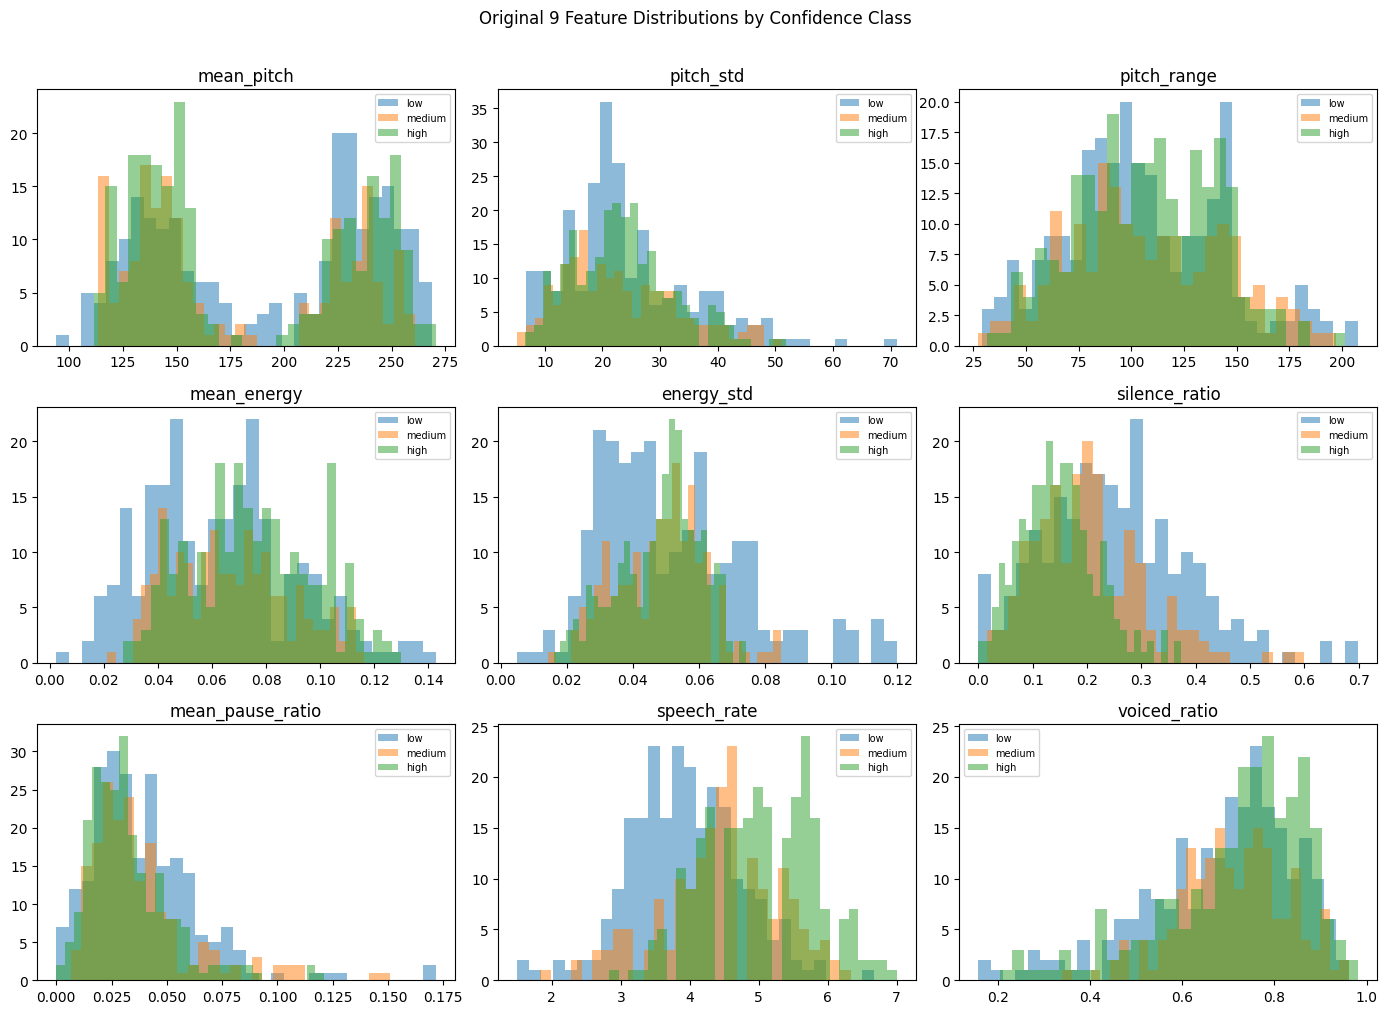

In [8]:
# Plot original 9 feature distributions
original_9 = FEATURE_NAMES[:9]
fig, axes  = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(original_9):
    for label in ['low', 'medium', 'high']:
        axes[i].hist(df[df['label'] == label][feat], alpha=0.5, bins=30, label=label)
    axes[i].set_title(feat)
    axes[i].legend(fontsize=7)

plt.suptitle('Original 9 Feature Distributions by Confidence Class', y=1.01)
plt.tight_layout()
plt.show()

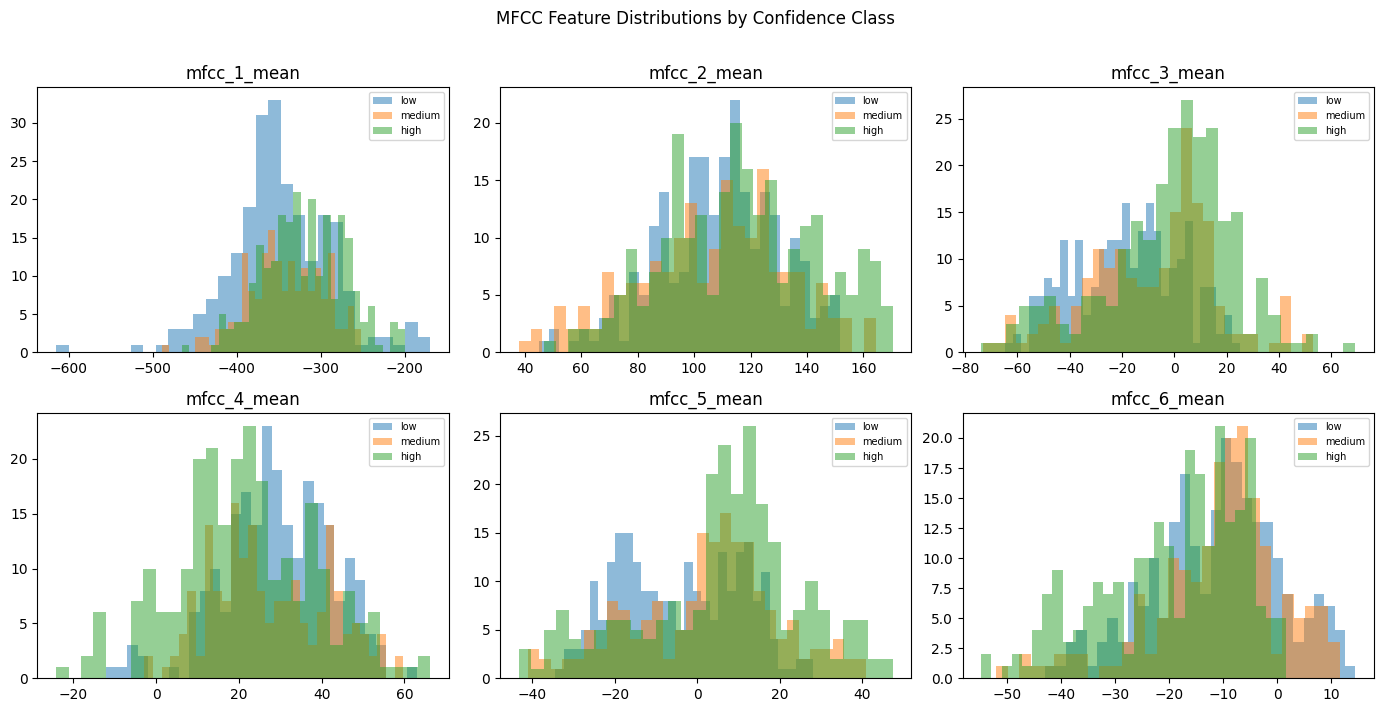

In [9]:
# Plot first 6 MFCCs
mfcc_feats = [f'mfcc_{i}_mean' for i in range(1, 7)]
fig, axes  = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i, feat in enumerate(mfcc_feats):
    for label in ['low', 'medium', 'high']:
        axes[i].hist(df[df['label'] == label][feat], alpha=0.5, bins=30, label=label)
    axes[i].set_title(feat)
    axes[i].legend(fontsize=7)

plt.suptitle('MFCC Feature Distributions by Confidence Class', y=1.01)
plt.tight_layout()
plt.show()

## 7. Prepare for Training

In [10]:
le = LabelEncoder()
X  = df[FEATURE_NAMES].values
y  = le.fit_transform(df['label'])

print('Classes :', le.classes_)

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train : {len(X_train)}  |  Test : {len(X_test)}')

Classes : ['high' 'low' 'medium']
Train : 528  |  Test : 132


## 8. Cross-Validation (SVM vs Logistic Regression)

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

svm_model = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
lr_model  = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)

svm_scores = cross_val_score(svm_model, X_scaled, y, cv=cv, scoring='accuracy')
lr_scores  = cross_val_score(lr_model,  X_scaled, y, cv=cv, scoring='accuracy')

print(f'SVM  CV Accuracy : {svm_scores.mean():.3f} ± {svm_scores.std():.3f}')
print(f'LR   CV Accuracy : {lr_scores.mean():.3f}  ± {lr_scores.std():.3f}')

SVM  CV Accuracy : 0.720 ± 0.026
LR   CV Accuracy : 0.665  ± 0.019


## 9. SVM Hyperparameter Tuning (GridSearchCV)

In [12]:
param_grid = {
    'C'     : [0.1, 1, 10, 100],
    'gamma' : ['scale', 'auto', 0.001, 0.01],
    'kernel': ['rbf', 'poly']
}

grid_search = GridSearchCV(
    SVC(class_weight='balanced', probability=True, random_state=42),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f'Best params   : {grid_search.best_params_}')
print(f'Best CV score : {grid_search.best_score_:.3f}')

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best params   : {'C': 10, 'gamma': 'auto', 'kernel': 'poly'}
Best CV score : 0.765


## 10. Train Final Model with Best Params

In [13]:
model = grid_search.best_estimator_

y_pred = model.predict(X_test)

print('--- Classification Report ---')
print(classification_report(y_test, y_pred, target_names=le.classes_))

--- Classification Report ---
              precision    recall  f1-score   support

        high       0.84      0.78      0.81        49
         low       0.73      0.74      0.74        47
      medium       0.62      0.67      0.64        36

    accuracy                           0.73       132
   macro avg       0.73      0.73      0.73       132
weighted avg       0.74      0.73      0.74       132



## 11. Confusion Matrix

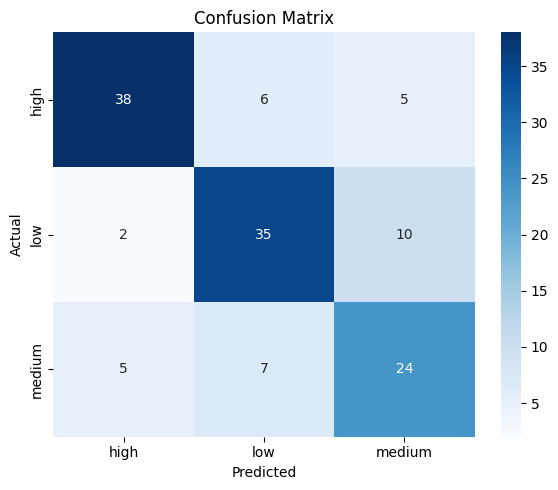

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

## 12. Feature Importance (via Permutation)

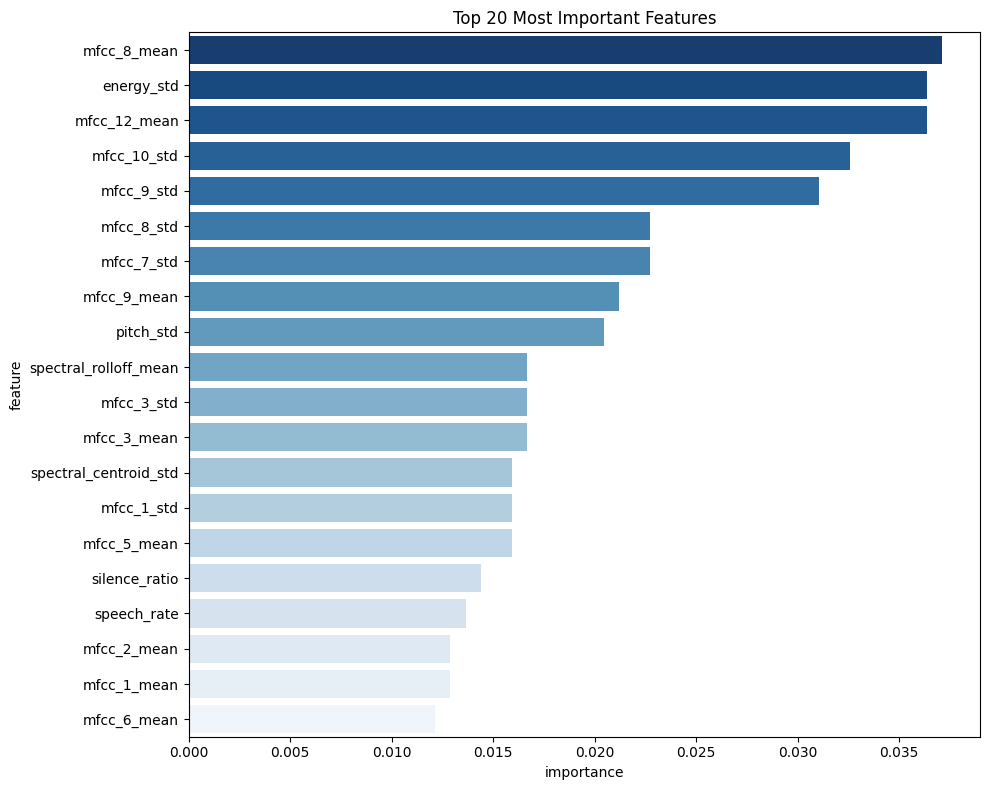

              feature  importance
          mfcc_8_mean    0.037121
           energy_std    0.036364
         mfcc_12_mean    0.036364
          mfcc_10_std    0.032576
           mfcc_9_std    0.031061
           mfcc_8_std    0.022727
           mfcc_7_std    0.022727
          mfcc_9_mean    0.021212
            pitch_std    0.020455
spectral_rolloff_mean    0.016667
           mfcc_3_std    0.016667
          mfcc_3_mean    0.016667
spectral_centroid_std    0.015909
           mfcc_1_std    0.015909
          mfcc_5_mean    0.015909
        silence_ratio    0.014394
          speech_rate    0.013636
          mfcc_2_mean    0.012879
          mfcc_1_mean    0.012879
          mfcc_6_mean    0.012121


In [16]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    model, X_test, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature'   : FEATURE_NAMES,
    'importance': result.importances_mean
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(20), x='importance', y='feature', palette='Blues_r')
plt.title('Top 20 Most Important Features')
plt.tight_layout()
plt.show()

print(importance_df.head(20).to_string(index=False))

## 13. Save Model

In [24]:
joblib.dump(model,  'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le,     'label_encoder.pkl')

print('Saved: model.pkl, scaler.pkl, label_encoder.pkl')

Saved: model.pkl, scaler.pkl, label_encoder.pkl


## 14. Inference on a Single Audio File

In [18]:
def predict_confidence(audio_path):
    """Run inference on a full answer clip (not pre-segmented).
    Segments internally, predicts per segment, aggregates by majority vote."""
    y, sr    = librosa.load(audio_path, sr=SR)
    segments = segment_audio(y, sr)

    if not segments:
        segments = [y]

    all_proba = []
    for seg in segments:
        feat     = extract_feature(seg, sr)
        x        = np.array(feat).reshape(1, -1)
        x_scaled = scaler.transform(x)
        all_proba.append(model.predict_proba(x_scaled)[0])

    # average probabilities across segments
    avg_proba = np.mean(all_proba, axis=0)
    prob_map  = dict(zip(le.classes_, avg_proba))

    confidence_score = (
        1.0 * prob_map.get('high',   0) +
        0.6 * prob_map.get('medium', 0) +
        0.2 * prob_map.get('low',    0)
    )

    return {
        'predicted_label'  : le.classes_[np.argmax(avg_proba)],
        'confidence_score' : round(float(confidence_score), 3),
        'probabilities'    : {k: round(float(v), 3) for k, v in prob_map.items()},
        'segments_analysed': len(segments)
    }


# Test on first clip
clip_files = sorted(f for f in os.listdir(CLIPS_DIR) if f.endswith('.wav'))
test_path  = os.path.join(CLIPS_DIR, clip_files[120])

result = predict_confidence(test_path)
print(f'File             : {clip_files[120]}')
print(f'Predicted label  : {result["predicted_label"]}')
print(f'Confidence score : {result["confidence_score"]}')
print(f'Probabilities    : {result["probabilities"]}')
print(f'Segments used    : {result["segments_analysed"]}')

File             : 133_mk4nhyNFLI0_MEDIUM.wav
Predicted label  : medium
Confidence score : 0.658
Probabilities    : {'high': 0.244, 'low': 0.1, 'medium': 0.656}
Segments used    : 5
